# 295. Find Median from Data Stream
**Difficulty:** 🔴 Hard · **Topic:** Heap · **Pattern:** [Two Heaps](README.md) · **LeetCode:** https://leetcode.com/problems/find-median-from-data-stream/

## 💡 Concepts

**Core concept(s):** Keep the numbers split into a **max-heap of the lower half** and a **min-heap of the upper half**.

**Why it applies here:** The median sits between the two halves. If the lower half's largest and the upper half's smallest are always at the top of two heaps (kept balanced in size), the median is one top (odd count) or the average of both tops (even count) — all in O(log n) per insert.

**Key intuition:** Balance a max-heap (low half) and a min-heap (high half); the median peeks at the tops.

---

### 📚 What is a Heap (Priority Queue)?
A **heap** always gives its smallest (min-heap) or largest (max-heap) item in **O(log n)**. Ideal for "keep the top K" or "always grab the current extreme".
- **In Python:** `heapq` (a min-heap; negate values for a max-heap).

---

### 📚 What is the median?
- **What it is:** the middle value once the numbers are sorted.
- **Odd count:** exactly one middle value. `[1, 3, 5]` → `3`.
- **Even count:** two middle values, so the median is their average. `[1, 3, 5, 15]` → `(3 + 5) / 2 = 4.0`.
- **Why it is awkward for a stream:** each new number can shift which value sits in the middle, so we need the middle without re-sorting everything.

---

### 📚 What is a sorted list + binary search (`bisect`)?
- **What it is:** a Python `list` kept in ascending order at all times.
- **How it works:** binary search halves the range on every comparison, so it finds where a new value belongs in `O(log n)` comparisons.
- **The catch:** inserting into the middle of a list shifts every later item one slot right, which costs `O(n)`.
- **Key operations:** find position `O(log n)`, insert `O(n)`, read any index (e.g. the middle) `O(1)`.
- **In Python:** `bisect.insort(lst, x)` = `bisect_right` + `list.insert`.

---

**Prerequisite knowledge:**
- Two heaps kept balanced.
- Negating values for a max-heap in Python.

## 📝 Problem

Design a class `MedianFinder` with three methods:
- `MedianFinder()` creates an empty structure.
- `addNum(num)` adds one integer from the stream.
- `findMedian()` returns the median of every number added so far (answers within `1e-5` of the true value are accepted).

**Example (LeetCode format)**
```
ops  = ["MedianFinder", "addNum", "addNum", "findMedian", "addNum", "findMedian"]
args = [[], [1], [2], [], [3], []]
out  = [null, null, null, 1.5, null, 2.0]
```
After `1, 2` the middle pair is `1, 2` → `1.5`. After `1, 2, 3` the middle value is `2`.

**Constraints**
- `-10^5 <= num <= 10^5`
- `findMedian` is only called after at least one `addNum`.
- At most `5 * 10^4` calls in total.

**Follow-ups (LeetCode):** what if every number is in `[0, 100]`? What if 99% of them are? (Answered in the pattern lesson's practice section.)

> Three approaches: re-sort on every query → keep one sorted list → two heaps (`O(log n)` add, `O(1)` median).

In [1]:
from typing import List, Optional
import heapq                       # binary min-heap on a plain list
import bisect                      # binary search on a sorted list
import random, statistics          # random streams + a reference median for the tests

def run_ops(cls, ops: List[str], args: List[list]) -> List[Optional[float]]:
    """Replay a LeetCode-style operation list against a MedianFinder-like class."""
    out, obj = [], None
    for op, a in zip(ops, args):
        if op == "MedianFinder":
            obj = cls(); out.append(None)          # constructor
        elif op == "addNum":
            obj.addNum(*a); out.append(None)       # addNum returns nothing
        else:
            out.append(obj.findMedian())           # findMedian returns the median
    return out

### Approach 1 — Brute Force: Sort on Every Query

**Idea:**
1. `addNum` just appends to a plain list.
2. `findMedian` sorts the list, then reads the middle value (odd count) or averages the middle two (even count).

**Time:** `addNum` `O(1)`. `findMedian` `O(n log n)` in general. Here the list is already sorted except for the values appended since the last query, and Python's Timsort spots that sorted run, so with one query per add each sort costs `O(n)`. Over `n` add + query pairs that is `O(n²)`.

**Space:** `O(n)` for the list.

In [2]:
class MedianFinderSort:
    """Brute force: store everything, sort when asked."""
    def __init__(self):
        self.nums = []
    def addNum(self, num: int) -> None:
        self.nums.append(num)                       # O(1): no order kept
    def findMedian(self) -> float:
        self.nums.sort()                            # put the stream in order every time we are asked
        n = len(self.nums)
        mid = n // 2
        if n % 2:                                   # odd count -> the single middle value
            return float(self.nums[mid])
        return (self.nums[mid - 1] + self.nums[mid]) / 2   # even count -> average the middle pair

### Approach 2 — Better: Keep One Sorted List (`bisect.insort`)

**Idea:**
1. Keep the list sorted at all times instead of sorting on demand.
2. `addNum` binary-searches the insertion point and inserts there.
3. `findMedian` reads the middle index directly.

**Time:** `addNum` `O(n)`: the search is `O(log n)`, but `list.insert` shifts every later item. `findMedian` `O(1)`. Over `n` adds: `O(n²)` (the shift is a fast memory move, so it only dominates once `n` is in the thousands).

**Space:** `O(n)`.

In [3]:
class MedianFinderInsort:
    """Better: the list is always sorted, so the median is an index lookup."""
    def __init__(self):
        self.nums = []
    def addNum(self, num: int) -> None:
        bisect.insort(self.nums, num)               # O(log n) to find the slot, O(n) to shift the tail right
    def findMedian(self) -> float:
        n = len(self.nums)
        mid = n // 2
        if n % 2:
            return float(self.nums[mid])            # O(1): direct index into the sorted list
        return (self.nums[mid - 1] + self.nums[mid]) / 2

### Approach 3 — Optimal: Two Heaps

**Idea:** `low` is a max-heap (store negatives) of the smaller half; `high` is a min-heap of the larger half.
1. Push the new number into `low`.
2. Move `low`'s largest into `high`. Now every value in `low` is `<=` every value in `high`.
3. If `high` got bigger than `low`, move `high`'s smallest back. So `low` holds the same count as `high`, or one more.
4. The median is `low`'s top (odd count) or the average of both tops (even count).

**Time:** `addNum` `O(log n)` (at most 3 heap pushes/pops), `findMedian` `O(1)`. **Space:** `O(n)`.

In [4]:
import heapq

class MedianFinder:
    """Keep the numbers split into a low half (max-heap) and a high half (min-heap)."""
    def __init__(self):
        self.low = []     # max-heap of the smaller half (Python heapq is min, so store negatives)
        self.high = []    # min-heap of the larger half
    def addNum(self, num: int) -> None:
        heapq.heappush(self.low, -num)                        # tentatively add to the low half
        heapq.heappush(self.high, -heapq.heappop(self.low))   # move its largest into the high half
        if len(self.high) > len(self.low):                    # keep the halves balanced in size
            heapq.heappush(self.low, -heapq.heappop(self.high))
    def findMedian(self) -> float:
        if len(self.low) > len(self.high):
            return float(-self.low[0])                        # odd count -> top of the bigger half
        return (-self.low[0] + self.high[0]) / 2              # even count -> average of both tops

In [5]:
# Correctness check
ops  = ["MedianFinder", "addNum", "addNum", "findMedian", "addNum", "findMedian"]
args = [[], [1], [2], [], [3], []]
expected = [None, None, None, 1.5, None, 2.0]
classes = [MedianFinderSort, MedianFinderInsort, MedianFinder]
for cls in classes:
    got = run_ops(cls, ops, args)
    print(f"{cls.__name__:<20} {got}")
    assert got == expected, (cls.__name__, got)

# The stream traced in the pattern lesson: medians after each add.
stream, want = [5, 15, 1, 3, 8], [5, 10.0, 5, 4.0, 5]
for cls in classes:
    mf = cls()
    for x, w in zip(stream, want):
        mf.addNum(x)
        assert mf.findMedian() == w, (cls.__name__, x)

# Edge cases: single value, negatives, duplicates.
for cls in classes:
    mf = cls(); mf.addNum(-7)
    assert mf.findMedian() == -7
    mf.addNum(-7); mf.addNum(-7)
    assert mf.findMedian() == -7
    mf.addNum(10)
    assert mf.findMedian() == -7          # [-7, -7, -7, 10] -> (-7 + -7) / 2

# Random streams against statistics.median, checking after every add.
rng = random.Random(0)
for _ in range(50):
    ref, finders = [], [cls() for cls in classes]
    for _ in range(rng.randint(1, 60)):
        x = rng.randint(-10**5, 10**5)
        ref.append(x)
        for mf in finders:
            mf.addNum(x)
            assert mf.findMedian() == statistics.median(ref)
print("\nAll tests passed")

MedianFinderSort     [None, None, None, 1.5, None, 2.0]
MedianFinderInsort   [None, None, None, 1.5, None, 2.0]
MedianFinder         [None, None, None, 1.5, None, 2.0]

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off the code, but it can be **measured**. We time each approach on streams of growing size `n` and read the **doubling ratio**: how much the runtime grows when `n` doubles.

| Theoretical (whole run) | Ratio `n` → `2n` |
|---|---|
| `O(n)`       | ≈ **2×** |
| `O(n log n)` | ≈ **2×** (slightly more) |
| `O(n²)`     | ≈ **4×** |

**Workload:** `n` calls to `addNum`, each followed by `findMedian` (a median after every number, like a live dashboard).

**Worst case:** a strictly **decreasing** stream. Every new number is the smallest so far, so `insort` inserts at index 0 and shifts the whole list, and the brute force re-sorts a list whose new value belongs at the very front. Expected: brute force and sorted list `O(n²)` (≈4×), two heaps `O(n log n)` (≈2×).


sort on query O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |      25.66 |           n/a
     8000 |     108.93 |         4.24x


    16000 |     386.41 |         3.55x


    32000 |    1489.70 |         3.86x

sorted list O(n^2)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       2.21 |           n/a
     8000 |       6.37 |         2.89x
    16000 |      24.63 |         3.86x
    32000 |     111.60 |         4.53x

two heaps O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       2.35 |           n/a
     8000 |       4.67 |         1.98x
    16000 |       9.80 |         2.10x
    32000 |      21.54 |         2.20x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


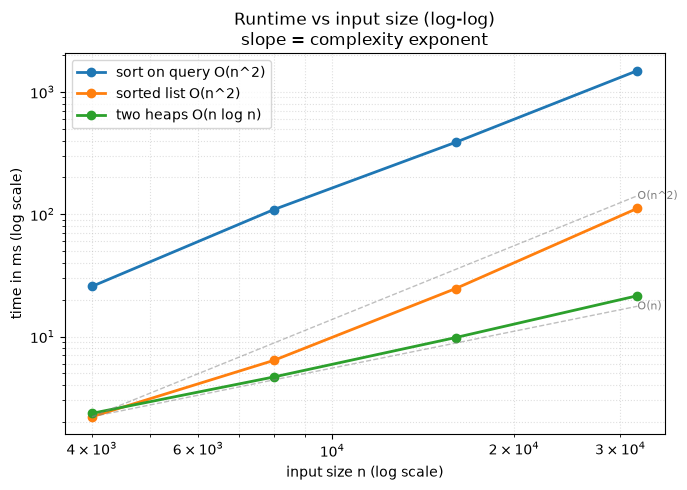

{'sort on query O(n^2)': [25.664458982646465,
  108.92770893406123,
  386.40670804306865,
  1489.699958008714],
 'sorted list O(n^2)': [2.208499936386943,
  6.374667049385607,
  24.63229198474437,
  111.5952079417184],
 'two heaps O(n log n)': [2.3546250304207206,
  4.66787489131093,
  9.7987080225721,
  21.538208005949855]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def stream_runner(cls):
    """n adds, a median after each one; returns the last median."""
    def run(nums):
        mf, last = cls(), None
        for x in nums:
            mf.addNum(x)
            last = mf.findMedian()
        return last
    return run

def make_worst_case(n):
    return (list(range(n, 0, -1)),)          # decreasing: each new value goes to the front

solutions = {
    "sort on query O(n^2)": stream_runner(MedianFinderSort),
    "sorted list O(n^2)":   stream_runner(MedianFinderInsort),
    "two heaps O(n log n)": stream_runner(MedianFinder),
}
sizes = [4000, 8000, 16000, 32000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Two Heaps](README.md) — the canonical template itself: a max-heap `low` and a min-heap `high` split the stream at the middle; push into `low`, move its top to `high`, rebalance so `len(low)` is `len(high)` or one more, and read the median from the tops.
- **Two balanced heaps straddle the middle:** the median is always at the tops.
- **Max-heap via negation:** Python only has a min-heap, so store negatives for the lower half.
- **Signal:** "running median / middle of a stream", "k-th around the center over time".
- **Sorted list as the stepping stone:** `bisect.insort` gives an `O(1)` median but pays `O(n)` per insert; the heaps only keep the two values next to the middle cheap to reach.
- **Related problems:** Sliding Window Median (LC 480, two heaps + lazy deletion), IPO (LC 502, two heaps used as a greedy picker), Kth Largest in a Stream (one heap, [Top K](../01_Top_K/README.md)).
- **Common pitfalls:** (1) letting the heaps get unbalanced; (2) wrong parity handling for even counts.